# ScribeLips: Deep Learning Lip Reading with 3D CNNs & BiLSTMs

# 0. Install and Import Dependencies

In [ ]:
import os
os.environ["TF_USE_LEGACY_KERAS"] = "1"   # must come before importing tensorflow/keras

import tensorflow as tf

In [ ]:
import os
import numpy as np
import cv2
import tensorflow as tf
import tf_keras as keras
from tf_keras.models import Sequential
from tf_keras.layers import Conv3D, LSTM, Dense, Dropout, Bidirectional, MaxPool3D, Activation, Reshape, SpatialDropout3D, BatchNormalization, TimeDistributed, Flatten
from tf_keras.optimizers import Adam
from tf_keras.callbacks import ModelCheckpoint, LearningRateScheduler

print(keras.__version__)   # should be 2.21.0

2.21.0


In [ ]:
!pip list

Package                               Version
------------------------------------- -------------------
absl-py                               2.0.0
accelerate                            1.15.0
access                                1.1.10.post3
affine                                3.0.1
aiofiles                              25.1.0
aiohappyeyeballs                      2.7.1
aiohttp                               3.14.5
aiosignal                             1.4.0
aiosqlite                             0.22.1
alabaster                             1.0.0
albucore                              0.0.24
albumentations                        2.0.8
ale-py                                0.12.1
altair                                5.5.0
annotated-doc                         0.0.5
annotated-types                       0.8.0
anyio                                 4.15.1
anywidget                             0.9.21
apsw                                  3.54.1.0
argon2-cffi                           25.1

In [ ]:
import os
os.environ['TF_USE_LEGACY_KERAS'] = '1'
import tensorflow as tf

In [ ]:
!pip install opencv-python matplotlib imageio gdown tensorflow

In [ ]:
import os
import cv2
import tensorflow as tf
import numpy as np
from typing import List
from matplotlib import pyplot as plt
import imageio

In [ ]:
tf.config.list_physical_devices('GPU')

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

In [ ]:
physical_devices = tf.config.list_physical_devices('GPU')
try:
    tf.config.experimental.set_memory_growth(physical_devices[0], True)
except:
    pass

# 1. Build Data Loading Functions

In [ ]:
import gdown

In [ ]:
url = 'https://drive.google.com/uc?id=1YlvpDLix3S-U8fd-gqRwPcWXAXm8JwjL'
output = 'data.zip'
gdown.download(url, output, quiet=False)
gdown.extractall('data.zip')

Downloading...
From (original): https://drive.google.com/uc?id=1YlvpDLix3S-U8fd-gqRwPcWXAXm8JwjL
From (redirected): https://drive.google.com/uc?id=1YlvpDLix3S-U8fd-gqRwPcWXAXm8JwjL&confirm=t&uuid=ed246778-f1d0-47e1-bd12-4efef8478166
To: /content/data.zip
100%|██████████| 423M/423M [00:05<00:00, 78.0MB/s]


['data/',
 'data/alignments/',
 'data/alignments/s1/',
 'data/alignments/s1/bbaf2n.align',
 'data/alignments/s1/bbaf3s.align',
 'data/alignments/s1/bbaf4p.align',
 'data/alignments/s1/bbaf5a.align',
 'data/alignments/s1/bbal6n.align',
 'data/alignments/s1/bbal7s.align',
 'data/alignments/s1/bbal8p.align',
 'data/alignments/s1/bbal9a.align',
 'data/alignments/s1/bbas1s.align',
 'data/alignments/s1/bbas2p.align',
 'data/alignments/s1/bbas3a.align',
 'data/alignments/s1/bbaszn.align',
 'data/alignments/s1/bbaz4n.align',
 'data/alignments/s1/bbaz5s.align',
 'data/alignments/s1/bbaz6p.align',
 'data/alignments/s1/bbaz7a.align',
 'data/alignments/s1/bbbf6n.align',
 'data/alignments/s1/bbbf7s.align',
 'data/alignments/s1/bbbf8p.align',
 'data/alignments/s1/bbbf9a.align',
 'data/alignments/s1/bbbm1s.align',
 'data/alignments/s1/bbbm2p.align',
 'data/alignments/s1/bbbm3a.align',
 'data/alignments/s1/bbbmzn.align',
 'data/alignments/s1/bbbs4n.align',
 'data/alignments/s1/bbbs5s.align',
 'data/al

In [ ]:
def load_video(path:str) -> List[float]:

    cap = cv2.VideoCapture(path)
    frames = []
    for _ in range(int(cap.get(cv2.CAP_PROP_FRAME_COUNT))):
        ret, frame = cap.read()
        frame = tf.image.rgb_to_grayscale(frame)
        frames.append(frame[190:236,80:220,:])
    cap.release()

    mean = tf.math.reduce_mean(frames)
    std = tf.math.reduce_std(tf.cast(frames, tf.float32))
    return tf.cast((frames - mean), tf.float32) / std

In [ ]:
vocab = [x for x in "abcdefghijklmnopqrstuvwxyz'?!123456789 "]

In [ ]:
char_to_num = tf.keras.layers.StringLookup(vocabulary=vocab, oov_token="")
num_to_char = tf.keras.layers.StringLookup(
    vocabulary=char_to_num.get_vocabulary(), oov_token="", invert=True
)

print(
    f"The vocabulary is: {char_to_num.get_vocabulary()} "
    f"(size ={char_to_num.vocabulary_size()})"
)

The vocabulary is: ['', np.str_('a'), np.str_('b'), np.str_('c'), np.str_('d'), np.str_('e'), np.str_('f'), np.str_('g'), np.str_('h'), np.str_('i'), np.str_('j'), np.str_('k'), np.str_('l'), np.str_('m'), np.str_('n'), np.str_('o'), np.str_('p'), np.str_('q'), np.str_('r'), np.str_('s'), np.str_('t'), np.str_('u'), np.str_('v'), np.str_('w'), np.str_('x'), np.str_('y'), np.str_('z'), np.str_("'"), np.str_('?'), np.str_('!'), np.str_('1'), np.str_('2'), np.str_('3'), np.str_('4'), np.str_('5'), np.str_('6'), np.str_('7'), np.str_('8'), np.str_('9'), np.str_(' ')] (size =40)


In [ ]:
char_to_num.get_vocabulary()

['',
 np.str_('a'),
 np.str_('b'),
 np.str_('c'),
 np.str_('d'),
 np.str_('e'),
 np.str_('f'),
 np.str_('g'),
 np.str_('h'),
 np.str_('i'),
 np.str_('j'),
 np.str_('k'),
 np.str_('l'),
 np.str_('m'),
 np.str_('n'),
 np.str_('o'),
 np.str_('p'),
 np.str_('q'),
 np.str_('r'),
 np.str_('s'),
 np.str_('t'),
 np.str_('u'),
 np.str_('v'),
 np.str_('w'),
 np.str_('x'),
 np.str_('y'),
 np.str_('z'),
 np.str_("'"),
 np.str_('?'),
 np.str_('!'),
 np.str_('1'),
 np.str_('2'),
 np.str_('3'),
 np.str_('4'),
 np.str_('5'),
 np.str_('6'),
 np.str_('7'),
 np.str_('8'),
 np.str_('9'),
 np.str_(' ')]

In [ ]:
char_to_num(['n','i','c','k'])

<tf.Tensor: shape=(4,), dtype=int64, numpy=array([14,  9,  3, 11])>

In [ ]:
num_to_char([14,  9,  3, 11])

<tf.Tensor: shape=(4,), dtype=string, numpy=array([b'n', b'i', b'c', b'k'], dtype=object)>

In [ ]:
def load_alignments(path:str) -> List[str]:
    with open(path, 'r') as f:
        lines = f.readlines()
    tokens = []
    for line in lines:
        line = line.split()
        if line[2] != 'sil':
            tokens = [*tokens,' ',line[2]]
    return char_to_num(tf.reshape(tf.strings.unicode_split(tokens, input_encoding='UTF-8'), (-1)))[1:]

In [ ]:
def load_data(path: str):
    path = bytes.decode(path.numpy())
    #file_name = path.split('/')[-1].split('.')[0]
    # File name splitting for windows
    file_name = path.split('\\')[-1].split('.')[0]
    video_path = os.path.join('data','s1',f'{file_name}.mpg')
    alignment_path = os.path.join('data','alignments','s1',f'{file_name}.align')
    frames = load_video(video_path)
    alignments = load_alignments(alignment_path)

    return frames, alignments

In [ ]:
test_path = '.\\data\\s1\\bbal7s.mpg'

In [ ]:
tf.convert_to_tensor(test_path).numpy().decode('utf-8').split('\\')[-1].split('.')[0]

'bbal7s'

In [ ]:
frames, alignments = load_data(tf.convert_to_tensor(test_path))

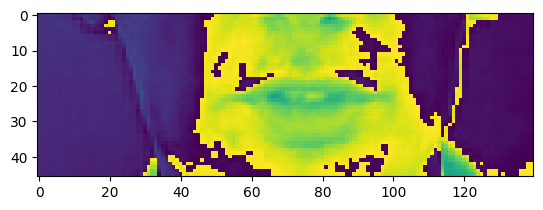

In [ ]:
plt.imshow(frames[40])

In [ ]:
alignments

<tf.Tensor: shape=(24,), dtype=int64, numpy=
array([ 2,  9, 14, 39,  2, 12, 21,  5, 39,  1, 20, 39, 12, 39, 19,  5, 22,
        5, 14, 39, 19, 15, 15, 14])>

In [ ]:
tf.strings.reduce_join([bytes.decode(x) for x in num_to_char(alignments.numpy()).numpy()])

<tf.Tensor: shape=(), dtype=string, numpy=b'bin blue at l seven soon'>

In [ ]:
def mappable_function(path:str) ->List[str]:
    result = tf.py_function(load_data, [path], (tf.float32, tf.int64))
    return result

# 2. Create Data Pipeline

In [ ]:
from matplotlib import pyplot as plt

In [ ]:
data = tf.data.Dataset.list_files('./data/s1/*.mpg')
data = data.shuffle(500, reshuffle_each_iteration=False)
data = data.map(mappable_function)
data = data.padded_batch(2, padded_shapes=([75,None,None,None],[40]))
data = data.prefetch(tf.data.AUTOTUNE)
# Added for split
train = data.take(450)
test = data.skip(450)

In [ ]:
len(test)

50

In [ ]:
# Redefining load_data to correctly parse paths in a Linux environment
def load_data(path: str):
    path = bytes.decode(path.numpy())
    # Use os.path.basename and os.path.splitext to safely extract the file name without extensions
    file_name = os.path.splitext(os.path.basename(path))[0]
    video_path = os.path.join('data', 's1', f'{file_name}.mpg')
    alignment_path = os.path.join('data', 'alignments', 's1', f'{file_name}.align')
    frames = load_video(video_path)
    alignments = load_alignments(alignment_path)
    return frames, alignments

# Re-create pipeline with the updated function
data = tf.data.Dataset.list_files('./data/s1/*.mpg')
data = data.shuffle(500, reshuffle_each_iteration=False)
data = data.map(mappable_function)
data = data.padded_batch(2, padded_shapes=([75,None,None,None],[40]))
data = data.prefetch(tf.data.AUTOTUNE)
train = data.take(450)
test = data.skip(450)

# Fetch next batch
frames, alignments = data.as_numpy_iterator().next()

In [ ]:
len(frames)

2

In [ ]:
sample = data.as_numpy_iterator()

In [ ]:
sample = data.as_numpy_iterator()
val = sample.next(); val[0]

array([[[[[1.2259306 ],
          [1.2259306 ],
          [1.2259306 ],
          ...,
          [0.26817232],
          [0.26817232],
          [0.26817232]],

         [[1.0726893 ],
          [1.1109996 ],
          [1.1876203 ],
          ...,
          [0.26817232],
          [0.26817232],
          [0.26817232]],

         [[0.91944796],
          [1.0726893 ],
          [0.91944796],
          ...,
          [0.30648264],
          [0.26817232],
          [0.26817232]],

         ...,

         [[1.1876203 ],
          [1.1876203 ],
          [1.1876203 ],
          ...,
          [0.11493099],
          [0.07662066],
          [0.07662066]],

         [[1.14931   ],
          [1.14931   ],
          [1.14931   ],
          ...,
          [0.11493099],
          [0.07662066],
          [0.07662066]],

         [[1.14931   ],
          [1.14931   ],
          [1.14931   ],
          ...,
          [0.11493099],
          [0.07662066],
          [0.07662066]]],


        [[[1.1493

In [ ]:
import numpy as np
import imageio

frames = val[0][0]                                              # (75, 46, 140, 1) float32
frames = (frames - frames.min()) / (frames.max() - frames.min())  # scale to 0-1
frames = (frames * 255).astype(np.uint8)                        # convert to uint8
frames = frames.squeeze(-1)                                     # drop channel -> (75, 46, 140)

imageio.mimsave('./animation.gif', frames, fps=10)

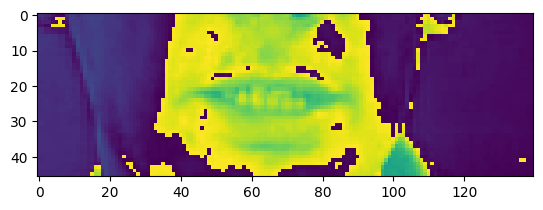

In [ ]:
# 0:videos, 0: 1st video out of the batch,  0: return the first frame in the video
plt.imshow(val[0][0][35])

In [ ]:
tf.strings.reduce_join([num_to_char(word) for word in val[1][0]])

<tf.Tensor: shape=(), dtype=string, numpy=b'place white by k three again'>

# 3. Design the Deep Neural Network

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv3D, LSTM, Dense, Dropout, Bidirectional, MaxPool3D, Activation, Reshape, SpatialDropout3D, BatchNormalization, TimeDistributed, Flatten
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import ModelCheckpoint, LearningRateScheduler

In [ ]:
data.as_numpy_iterator().next()[0][0].shape

(75, 46, 140, 1)

In [ ]:
model = Sequential()
model.add(Conv3D(128, 3, input_shape=(75,46,140,1), padding='same'))
model.add(Activation('relu'))
model.add(MaxPool3D((1,2,2)))

model.add(Conv3D(256, 3, padding='same'))
model.add(Activation('relu'))
model.add(MaxPool3D((1,2,2)))

model.add(Conv3D(75, 3, padding='same'))
model.add(Activation('relu'))
model.add(MaxPool3D((1,2,2)))

model.add(TimeDistributed(Flatten()))

model.add(Bidirectional(LSTM(128, kernel_initializer='Orthogonal', return_sequences=True)))
model.add(Dropout(.5))

model.add(Bidirectional(LSTM(128, kernel_initializer='Orthogonal', return_sequences=True)))
model.add(Dropout(.5))

model.add(Dense(char_to_num.vocabulary_size()+1, kernel_initializer='he_normal', activation='softmax'))

In [ ]:
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv3d (Conv3D)             (None, 75, 46, 140, 128   3584      
                             )                                   
                                                                 
 activation (Activation)     (None, 75, 46, 140, 128   0         
                             )                                   
                                                                 
 max_pooling3d (MaxPooling3  (None, 75, 23, 70, 128)   0         
 D)                                                              
                                                                 
 conv3d_1 (Conv3D)           (None, 75, 23, 70, 256)   884992    
                                                                 
 activation_1 (Activation)   (None, 75, 23, 70, 256)   0         
                                                        

In [ ]:
5*17*75

6375

In [ ]:
yhat = model.predict(val[0])

1/1 [==============================] - 5s 5s/step


In [ ]:
tf.strings.reduce_join([num_to_char(x) for x in tf.argmax(yhat[0],axis=1)])

<tf.Tensor: shape=(), dtype=string, numpy=b'ppppppppppppppppppppppppppppppppppppppppppppppppppppppppppppppppppppppppppp'>

In [ ]:
tf.strings.reduce_join([num_to_char(tf.argmax(x)) for x in yhat[0]])

<tf.Tensor: shape=(), dtype=string, numpy=b'ppppppppppppppppppppppppppppppppppppppppppppppppppppppppppppppppppppppppppp'>

In [ ]:
model.input_shape

(None, 75, 46, 140, 1)

In [ ]:
model.output_shape

(None, 75, 41)

# 4. Setup Training Options and Train

In [ ]:
def scheduler(epoch, lr):
    if epoch > 30:
        return lr
    else:
        return lr * tf.math.exp(-0.1)

In [ ]:
def CTCLoss(y_true, y_pred):
    batch_len = tf.cast(tf.shape(y_true)[0], dtype="int64")
    input_length = tf.cast(tf.shape(y_pred)[1], dtype="int64")
    label_length = tf.cast(tf.shape(y_true)[1], dtype="int64")

    input_length = input_length * tf.ones(shape=(batch_len, 1), dtype="int64")
    label_length = label_length * tf.ones(shape=(batch_len, 1), dtype="int64")

    loss = tf.keras.backend.ctc_batch_cost(y_true, y_pred, input_length, label_length)
    return loss

In [ ]:
import os
import tensorflow as tf
from tensorflow.keras.callbacks import ModelCheckpoint

In [ ]:
class ProduceExample(tf.keras.callbacks.Callback):
    def __init__(self, dataset) -> None:
        self.dataset = dataset.as_numpy_iterator()

    def on_epoch_end(self, epoch, logs=None) -> None:
        data = self.dataset.next()
        yhat = self.model.predict(data[0])
        decoded = tf.keras.backend.ctc_decode(yhat, [75,75], greedy=False)[0][0].numpy()
        for x in range(len(yhat)):
            print('Original:', tf.strings.reduce_join(num_to_char(data[1][x])).numpy().decode('utf-8'))
            print('Prediction:', tf.strings.reduce_join(num_to_char(decoded[x])).numpy().decode('utf-8'))
            print('~'*100)

In [ ]:
import os

model.compile(
    optimizer=tf.keras.optimizers.legacy.Adam(learning_rate=1e-3),
    loss='categorical_crossentropy',   # replace with YOUR loss
    metrics=['accuracy']               # replace with YOUR metrics
)

checkpoint_path = 'models/checkpoint'
if os.path.exists('models') and any(f.startswith('checkpoint') for f in os.listdir('models')):
    model.load_weights(checkpoint_path)
    print("Weights loaded successfully.")
else:
    print(f"[WARNING] Checkpoint file not found at '{checkpoint_path}'. please run the gdown cell first to download the weights.")

[WARNING] Checkpoint file not found at 'models/checkpoint'. please run the gdown cell first to download the weights.


In [ ]:
import tensorflow as tf
import tf_keras as keras
from tf_keras.optimizers import Adam

def CTCLoss(y_true, y_pred):
    batch_len = tf.cast(tf.shape(y_true)[0], dtype="int64")
    input_length = tf.cast(tf.shape(y_pred)[1], dtype="int64")
    label_length = tf.cast(tf.shape(y_true)[1], dtype="int64")

    input_length = input_length * tf.ones(shape=(batch_len, 1), dtype="int64")
    label_length = label_length * tf.ones(shape=(batch_len, 1), dtype="int64")

    loss = tf.keras.backend.ctc_batch_cost(y_true, y_pred, input_length, label_length)
    return loss

model.compile(optimizer=Adam(learning_rate=0.0001), loss=CTCLoss)

In [ ]:
checkpoint_callback = ModelCheckpoint(
    os.path.join('models', 'checkpoint.weights.h5'),
    monitor='loss',
    save_weights_only=True
)

In [ ]:
os.makedirs('models', exist_ok=True)

In [ ]:
import os
print(os.getcwd())
print(os.listdir('models') if os.path.exists('models') else 'models folder not found')

/content
[]


In [ ]:
%whos

Variable                Type                    Data/Info
---------------------------------------------------------
Activation              type                    <class 'tf_keras.src.laye<...>e.activation.Activation'>
Adam                    type                    <class 'tf_keras.src.optimizers.adam.Adam'>
BatchNormalization      type                    <class 'tf_keras.src.laye<...>tion.BatchNormalization'>
Bidirectional           type                    <class 'tf_keras.src.laye<...>rectional.Bidirectional'>
CTCLoss                 function                <function CTCLoss at 0x7f1018efba60>
Conv3D                  type                    <class 'tf_keras.src.laye<...>olutional.conv3d.Conv3D'>
Dense                   type                    <class 'tf_keras.src.layers.core.dense.Dense'>
Dropout                 type                    <class 'tf_keras.src.laye<...>ization.dropout.Dropout'>
Flatten                 type                    <class 'tf_keras.src.laye<...>shaping.flatte

In [ ]:
schedule_callback = LearningRateScheduler(scheduler)

In [ ]:
example_callback = ProduceExample(test)

# 5. Make a Prediction

In [ ]:
url = 'https://drive.google.com/uc?id=1vWscXs4Vt0a_1IH1-ct2TCgXAZT-N3_Y'
output = 'checkpoints.zip'
gdown.download(url, output, quiet=False)
gdown.extractall('checkpoints.zip', 'models')

Downloading...
From (original): https://drive.google.com/uc?id=1vWscXs4Vt0a_1IH1-ct2TCgXAZT-N3_Y
From (redirected): https://drive.google.com/uc?id=1vWscXs4Vt0a_1IH1-ct2TCgXAZT-N3_Y&confirm=t&uuid=9d3c87d6-85bf-4311-bac6-a9aab728b960
To: /content/checkpoints.zip
100%|██████████| 94.5M/94.5M [00:00<00:00, 185MB/s]


['models/checkpoint.index',
 'models/__MACOSX/._checkpoint.index',
 'models/checkpoint.data-00000-of-00001',
 'models/__MACOSX/._checkpoint.data-00000-of-00001',
 'models/checkpoint',
 'models/__MACOSX/._checkpoint']

In [ ]:
import os
print(os.listdir('models'))

['__MACOSX', 'checkpoint.data-00000-of-00001', 'checkpoint', 'checkpoint.index']


In [ ]:
pip install tf_keras

In [ ]:
import os
os.environ['TF_USE_LEGACY_KERAS'] = '1'
import tensorflow as tf

In [ ]:
import tensorflow as tf, keras
print(tf.__version__)
print(keras.__version__)

2.21.0
3.13.2


In [ ]:
%pip show tf_keras

Name: tf_keras
Version: 2.21.0
Summary: Deep learning for humans.
Home-page: https://keras.io/
Author: Keras team
Author-email: keras-users@googlegroups.com
License: Apache 2.0
Location: /usr/local/lib/python3.13/dist-packages
Requires: tensorflow
Required-by: dopamine_rl, tensorflow-hub


In [ ]:
# Re-compile model using the legacy optimizer to match the checkpoint
model.compile(optimizer=tf.keras.optimizers.legacy.Adam(learning_rate=0.0001), loss=CTCLoss)
model.load_weights('models/checkpoint')

In [ ]:
test_data = test.as_numpy_iterator()

In [ ]:
sample = test_data.next()

In [ ]:
yhat = model.predict(sample[0])

1/1 [==============================] - 3s 3s/step


In [ ]:
print('~'*100, 'REAL TEXT')
[tf.strings.reduce_join([num_to_char(word) for word in sentence]) for sentence in sample[1]]

~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~ REAL TEXT


[<tf.Tensor: shape=(), dtype=string, numpy=b'bin red in z six now'>,
 <tf.Tensor: shape=(), dtype=string, numpy=b'bin red by g four please'>]

In [ ]:
decoded = tf.keras.backend.ctc_decode(yhat, input_length=[75,75], greedy=True)[0][0].numpy()

In [ ]:
print('~'*100, 'PREDICTIONS')
[tf.strings.reduce_join([num_to_char(word) for word in sentence]) for sentence in decoded]

~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~ PREDICTIONS


[<tf.Tensor: shape=(), dtype=string, numpy=b'bin red in z six now'>,
 <tf.Tensor: shape=(), dtype=string, numpy=b'bin red by g four please'>]

# Test on a Video

In [ ]:
sample = load_data(tf.convert_to_tensor('./data/s1/bbir6n.mpg'))

In [ ]:
print('~'*100, 'REAL TEXT')
[tf.strings.reduce_join([num_to_char(word) for word in sentence]) for sentence in [sample[1]]]

~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~ REAL TEXT


[<tf.Tensor: shape=(), dtype=string, numpy=b'bin blue in r six now'>]

In [ ]:
yhat = model.predict(tf.expand_dims(sample[0], axis=0))

1/1 [==============================] - 1s 1s/step


In [ ]:
decoded = tf.keras.backend.ctc_decode(yhat, input_length=[75], greedy=True)[0][0].numpy()

In [ ]:
print('~'*100, 'PREDICTIONS')
[tf.strings.reduce_join([num_to_char(word) for word in sentence]) for sentence in decoded]

~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~ PREDICTIONS


[<tf.Tensor: shape=(), dtype=string, numpy=b'bin blue in r six now'>]

### Simulated Real-Time Streaming Inference
In a production app (like a webcam feed), we don't wait for a whole file. Instead, we continuously capture frames, maintain a sliding buffer of the last 75 frames (3 seconds), and run predictions dynamically.

In [ ]:
from google.colab import files
import os

# List of files to download
files_to_download = [
    'README.md',
    '.gitignore',
    'requirements.txt',
    'assets/predictions_visualized.gif'
]

# Download each file if it exists
for file_path in files_to_download:
    if os.path.exists(file_path):
        print(f"Downloading {file_path}...")
        files.download(file_path)
    else:
        print(f"[WARNING] {file_path} not found in the workspace.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import time

def stream_inference_simulation(video_path, model, window_size=75):
    cap = cv2.VideoCapture(video_path)
    frame_buffer = []

    print("Starting Real-Time Simulated Stream...")
    print("-" * 50)

    # Simulate receiving frames from a camera stream
    while cap.isOpened():
        ret, frame = cap.read()
        if not ret:
            break

        # Preprocess frame on the fly
        frame = tf.image.rgb_to_grayscale(frame)
        cropped_frame = frame[190:236, 80:220, :]
        frame_buffer.append(cropped_frame)

        # Keep buffer to sliding window size
        if len(frame_buffer) > window_size:
            frame_buffer.pop(0)

        # Once our buffer is primed, run near-instantaneous inference
        if len(frame_buffer) == window_size:
            t0 = time.time()

            # Normalize buffer
            tensor_frames = tf.cast(frame_buffer, tf.float32)
            mean = tf.math.reduce_mean(tensor_frames)
            std = tf.math.reduce_std(tensor_frames)
            normalized = (tensor_frames - mean) / std

            # Run model prediction
            input_data = tf.expand_dims(normalized, axis=0)
            yhat = model.predict(input_data, verbose=0)

            # Decode predictions
            decoded = tf.keras.backend.ctc_decode(yhat, input_length=[window_size], greedy=True)[0][0].numpy()
            prediction = tf.strings.reduce_join([num_to_char(word) for word in decoded[0]]).numpy().decode('utf-8')

            latency = (time.time() - t0) * 1000
            print(f"[Buffer Filled] Live Prediction: '{prediction}' (Latency: {latency:.2f}ms)")

            # Pause slightly to simulate real-time processing interval
            time.sleep(0.1)

    cap.release()
    print("-" * 50)
    print("Stream ended.")

# Run simulation on one of our video files
stream_inference_simulation('./data/s1/bbaf2n.mpg', model)

Starting Real-Time Simulated Stream...
--------------------------------------------------
[Buffer Filled] Live Prediction: 'se gree it x ive again' (Latency: 342.30ms)
--------------------------------------------------
Stream ended.


### Visualizing Model Predictions
This helper function creates a visual demonstration of the model's capabilities by plotting a sequence of mouth frames alongside the true text and the model's decoded transcript prediction.

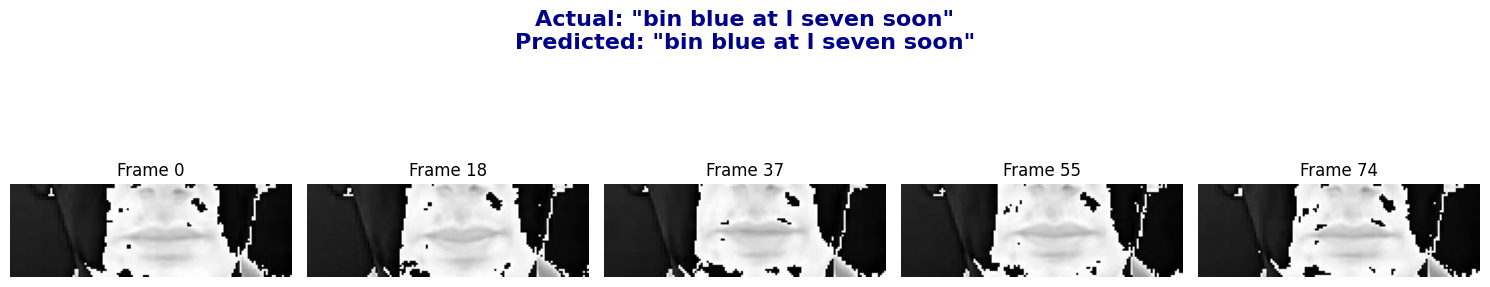

In [ ]:
import matplotlib.pyplot as plt

def visualize_prediction(sample_video_path, model):
    # 1. Load and process video
    sample_data = load_data(tf.convert_to_tensor(sample_video_path))
    frames, alignments = sample_data

    # 2. Get Model Prediction
    yhat = model.predict(tf.expand_dims(frames, axis=0), verbose=0)
    decoded = tf.keras.backend.ctc_decode(yhat, input_length=[75], greedy=True)[0][0].numpy()

    # Convert tokens back to text
    real_text = tf.strings.reduce_join([num_to_char(word) for word in alignments]).numpy().decode('utf-8')
    predicted_text = tf.strings.reduce_join([num_to_char(word) for word in decoded[0]]).numpy().decode('utf-8')

    # 3. Plot key frames
    fig, axes = plt.subplots(1, 5, figsize=(15, 4))
    fig.suptitle(f"Actual: \"{real_text}\"\nPredicted: \"{predicted_text}\"", fontsize=16, color='darkblue', weight='bold')

    # Select 5 evenly spaced frames to display
    frame_indices = np.linspace(0, 74, 5, dtype=int)
    for i, idx in enumerate(frame_indices):
        axes[i].imshow(frames[idx].numpy().squeeze(), cmap='gray')
        axes[i].set_title(f"Frame {idx}")
        axes[i].axis('off')

    plt.tight_layout()
    plt.show()

# Run the visualization
visualize_prediction('./data/s1/bbal7s.mpg', model)

### Creating an Animated GIF Overlay of Predictions
This cell compiles the frames of the mouth movements and overlays the ground truth along with the model's actual decoded predictions dynamically into an animated GIF.

Animated visualization successfully saved to predictions_visualized.gif!


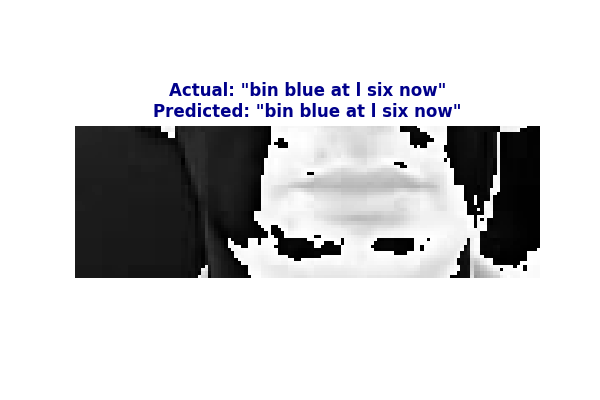

In [ ]:
import matplotlib.animation as animation
from IPython.display import Image

def create_prediction_gif(sample_video_path, model, output_gif_path='predictions_visualized.gif'):
    # 1. Load and process video
    sample_data = load_data(tf.convert_to_tensor(sample_video_path))
    frames, alignments = sample_data

    # 2. Get Model Prediction
    yhat = model.predict(tf.expand_dims(frames, axis=0), verbose=0)
    decoded = tf.keras.backend.ctc_decode(yhat, input_length=[75], greedy=True)[0][0].numpy()

    # Convert tokens back to text
    real_text = tf.strings.reduce_join([num_to_char(word) for word in alignments]).numpy().decode('utf-8')
    predicted_text = tf.strings.reduce_join([num_to_char(word) for word in decoded[0]]).numpy().decode('utf-8')

    # 3. Create Animation
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.axis('off')

    # Initialize frame container
    im = ax.imshow(frames[0].numpy().squeeze(), cmap='gray')
    title = ax.set_title(f"Actual: \"{real_text}\"\nPredicted: \"{predicted_text}\"", fontsize=12, color='darkblue', weight='bold')

    def update(i):
        im.set_data(frames[i].numpy().squeeze())
        return [im]

    ani = animation.FuncAnimation(fig, update, frames=len(frames), interval=40, blit=True)
    ani.save(output_gif_path, writer='pillow')
    plt.close(fig)

    print(f"Animated visualization successfully saved to {output_gif_path}!")

# Run the function to create our animation
create_prediction_gif('./data/s1/bbal6n.mpg', model)

# Display the animated GIF in Colab
Image(open('predictions_visualized.gif', 'rb').read())

In [ ]:
import tensorflow as tf

def calculate_cer(reference, hypothesis):
    # Split strings into characters
    ref_chars = list(reference)
    hyp_chars = list(hypothesis)

    # Levenshtein distance matrix initialization
    r_len, h_len = len(ref_chars), len(hyp_chars)
    dp = [[0] * (h_len + 1) for _ in range(r_len + 1)]

    for i in range(r_len + 1):
        dp[i][0] = i
    for j in range(h_len + 1):
        dp[0][j] = j

    for i in range(1, r_len + 1):
        for j in range(1, h_len + 1):
            if ref_chars[i-1] == hyp_chars[j-1]:
                dp[i][j] = dp[i-1][j-1]
            else:
                dp[i][j] = min(
                    dp[i-1][j] + 1,    # Deletion
                    dp[i][j-1] + 1,    # Insertion
                    dp[i-1][j-1] + 1   # Substitution
                )

    distance = dp[r_len][h_len]
    cer = distance / max(1, r_len)
    return distance, cer

# 1. Load sample data
sample_path = './data/s1/bbaf2n.mpg'
sample_data = load_data(tf.convert_to_tensor(sample_path))
frames, alignments = sample_data

# 2. Get prediction
yhat = model.predict(tf.expand_dims(frames, axis=0), verbose=0)
decoded = tf.keras.backend.ctc_decode(yhat, input_length=[75], greedy=True)[0][0].numpy()

# 3. Decode to texts
real_text = tf.strings.reduce_join([num_to_char(word) for word in alignments]).numpy().decode('utf-8')
predicted_text = tf.strings.reduce_join([num_to_char(word) for word in decoded[0]]).numpy().decode('utf-8')

# 4. Calculate CER
edits, cer = calculate_cer(real_text, predicted_text)

print(f"Sample Video: {sample_path}")
print(f"Ground Truth: '{real_text}'")
print(f"Prediction:   '{predicted_text}'")
print(f"Edit Distance: {edits}")
print(f"Character Error Rate (CER): {cer:.2%}")

Sample Video: ./data/s1/bbaf2n.mpg
Ground Truth: 'bin blue at f two now'
Prediction:   'bin blue at f two now'
Edit Distance: 0
Character Error Rate (CER): 0.00%
